In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
import missingno as msno
%matplotlib inline

In [5]:
df = pd.read_csv('/data/titanic.csv')

In [6]:
print(df.shape)
print(df.info())    #输出列名 有效非空数量 数据类型
print(df.describe())

(1309, 14)
<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   pclass     1309 non-null   int64  
 1   survived   1309 non-null   int64  
 2   name       1309 non-null   str    
 3   sex        1309 non-null   str    
 4   age        1046 non-null   float64
 5   sibsp      1309 non-null   int64  
 6   parch      1309 non-null   int64  
 7   ticket     1309 non-null   str    
 8   fare       1308 non-null   float64
 9   cabin      295 non-null    str    
 10  embarked   1307 non-null   str    
 11  boat       486 non-null    str    
 12  body       121 non-null    float64
 13  home.dest  745 non-null    str    
dtypes: float64(3), int64(4), str(7)
memory usage: 143.3 KB
None
            pclass     survived          age        sibsp        parch  \
count  1309.000000  1309.000000  1046.000000  1309.000000  1309.000000   
mean      2.294882     0.381971    29.88

In [7]:
print(df.isnull().sum())    #查看缺失值的数量

pclass          0
survived        0
name            0
sex             0
age           263
sibsp           0
parch           0
ticket          0
fare            1
cabin        1014
embarked        2
boat          823
body         1188
home.dest     564
dtype: int64


In [8]:
missing_percentage = df.isnull().sum() / len(df) * 100
print(missing_percentage.sort_values(ascending = False))

body         90.756303
cabin        77.463713
boat         62.872422
home.dest    43.086325
age          20.091673
embarked      0.152788
fare          0.076394
sibsp         0.000000
name          0.000000
survived      0.000000
pclass        0.000000
sex           0.000000
parch         0.000000
ticket        0.000000
dtype: float64


<Axes: >

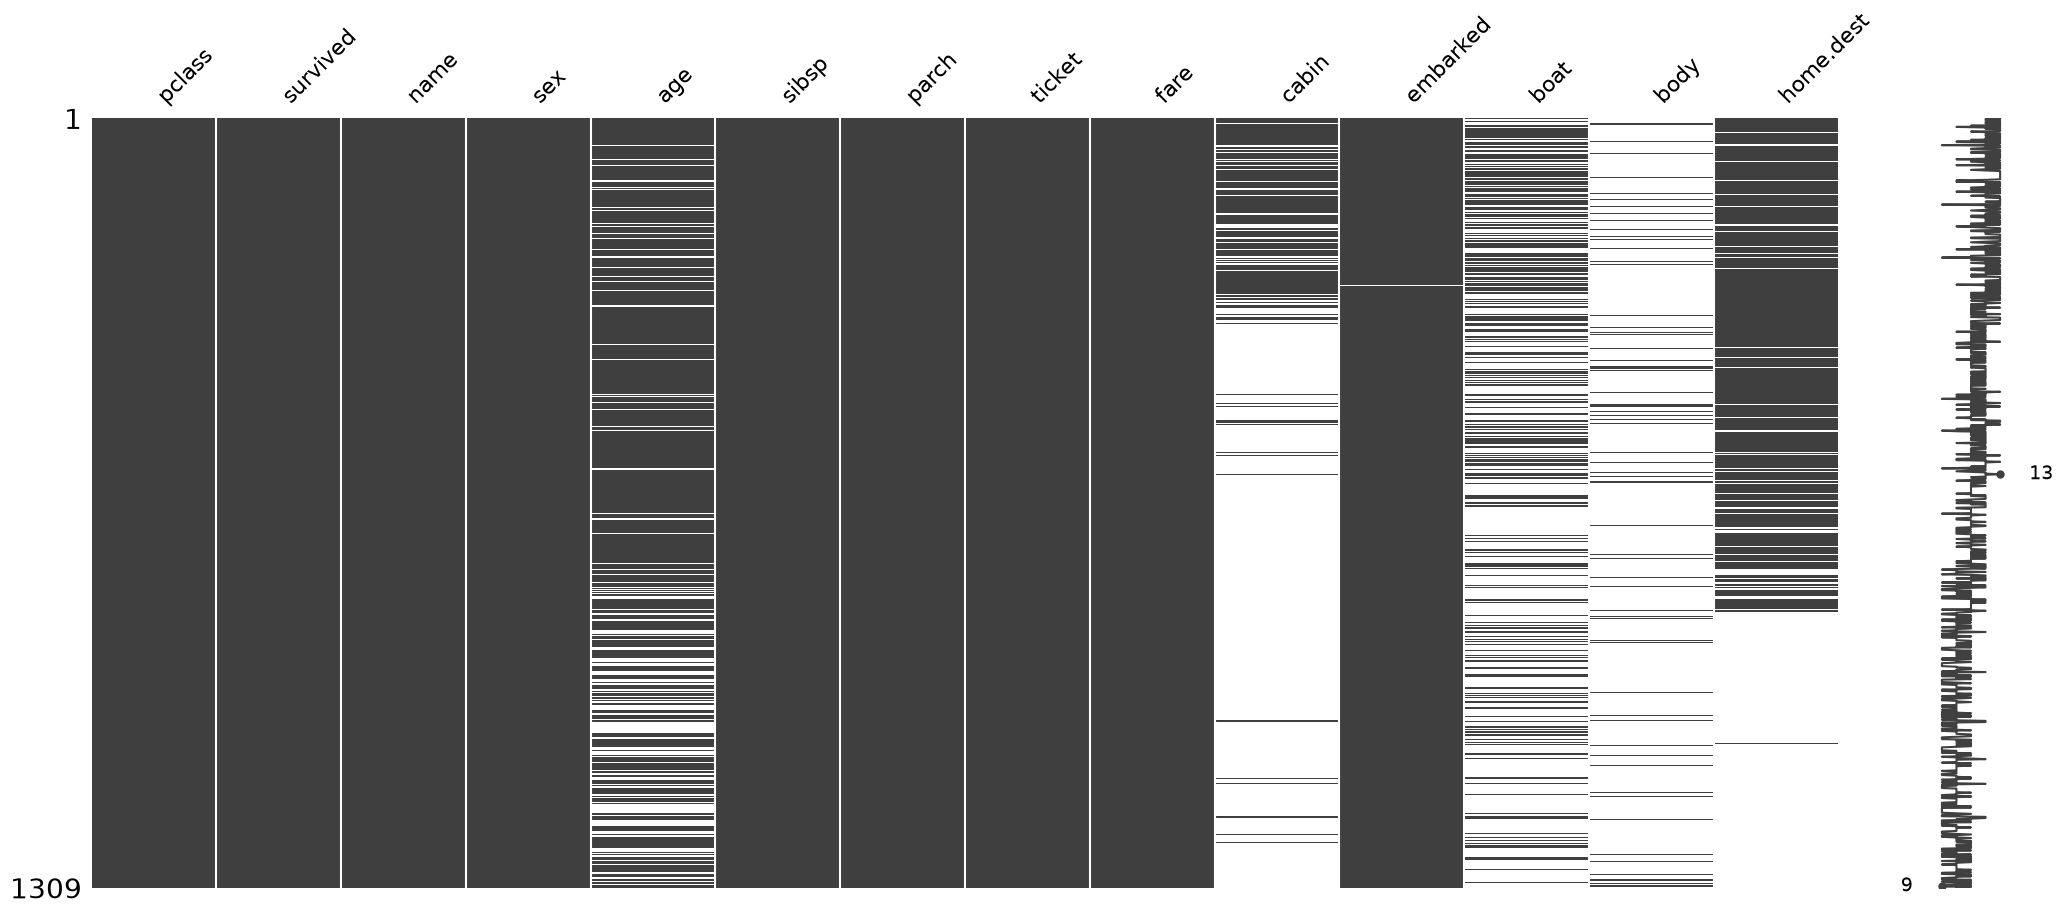

In [9]:
msno.matrix(df)

<Axes: >

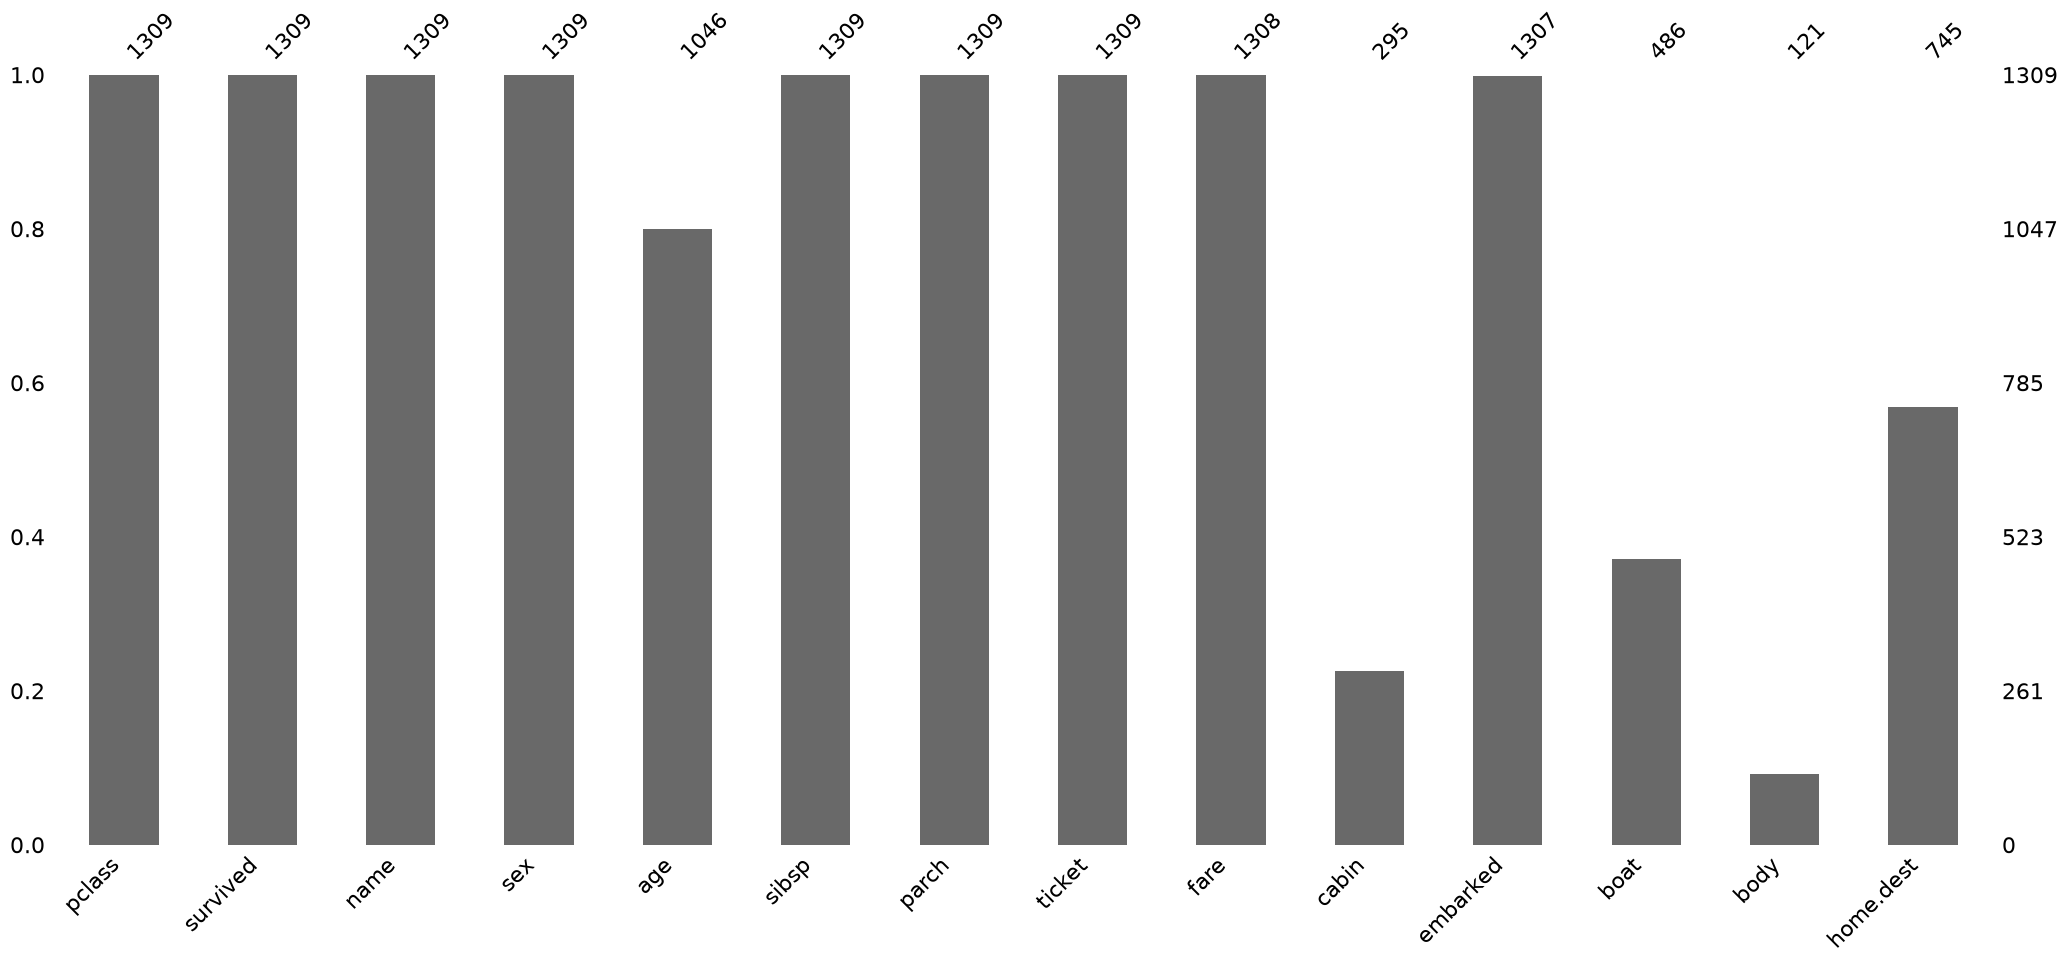

In [10]:
msno.bar(df)

<Axes: >

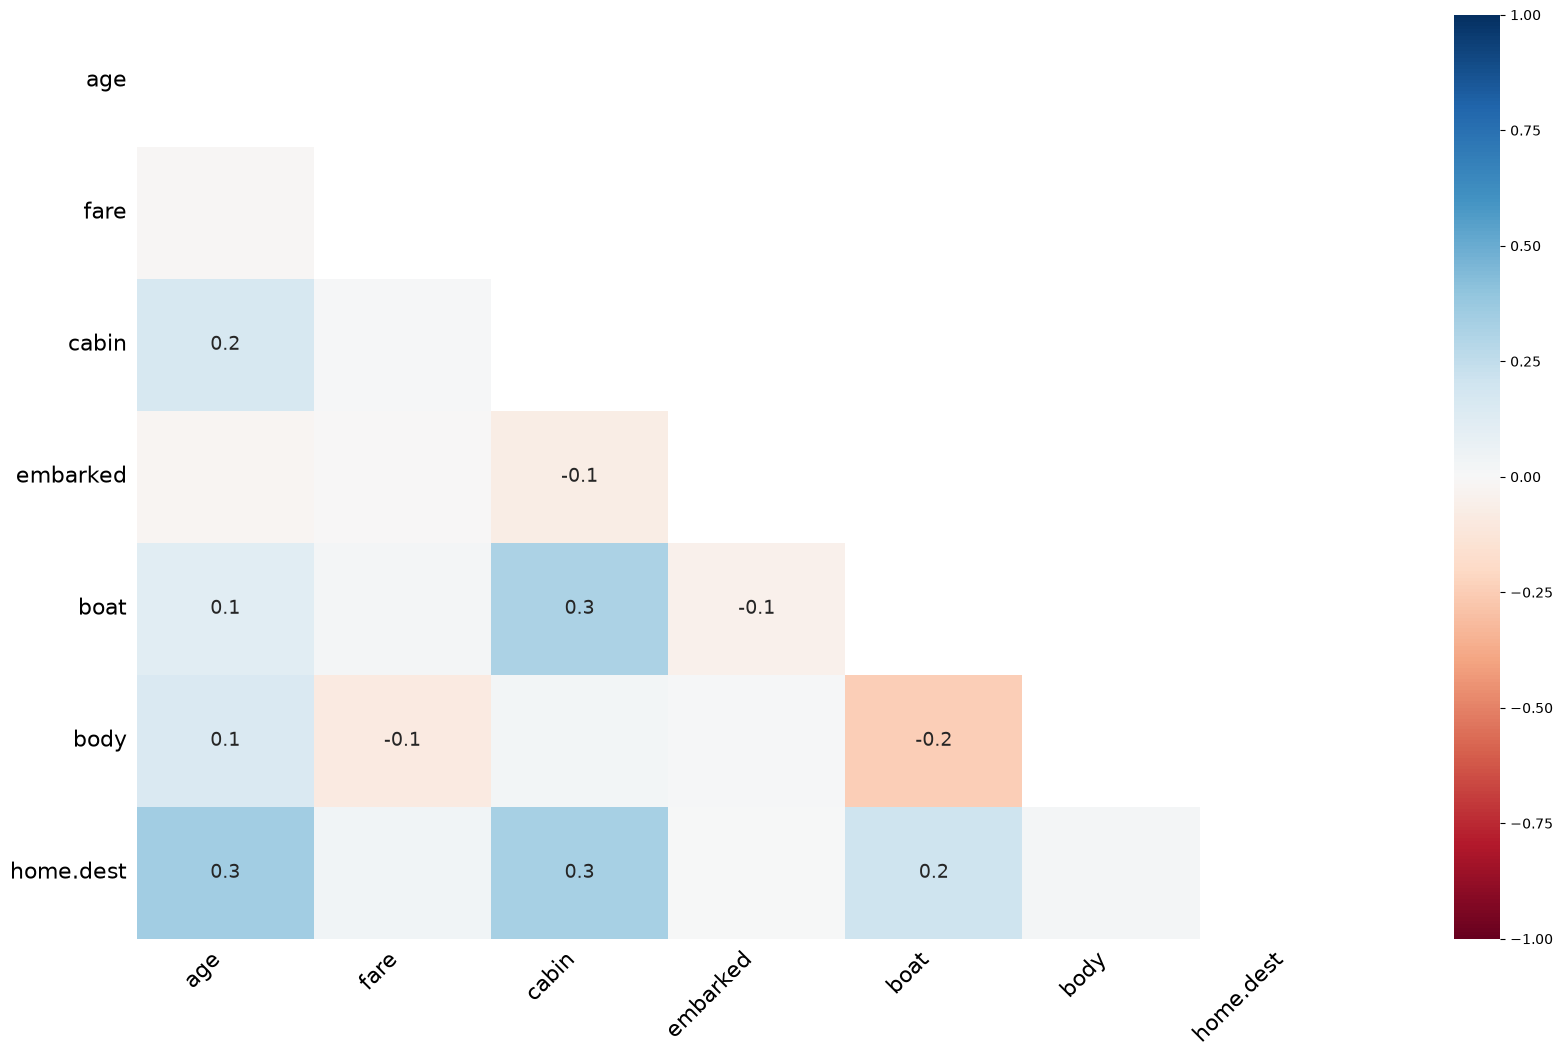

In [11]:
msno.heatmap(df)     # 缺失相关性热图

In [12]:
df = df.drop(columns = ['body' , 'cabin' , 'boat' , 'home.dest'])

In [13]:
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,S
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,S
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,S
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,S
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,S
...,...,...,...,...,...,...,...,...,...,...
1304,3,0,"Zabour, Miss. Hileni",female,14.5000,1,0,2665,14.4542,C
1305,3,0,"Zabour, Miss. Thamine",female,NaN,1,0,2665,14.4542,C
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.5000,0,0,2656,7.2250,C
1307,3,0,"Zakarian, Mr. Ortin",male,27.0000,0,0,2670,7.2250,C


In [14]:
#处理乘客登船的港口信息（用众数填充）
embark_mode_series = df['embarked'].mode()
most_freq_port = embark_mode_series[0]
df['embarked'] = df['embarked'].fillna(most_freq_port)
print(df['embarked'])

0       S
1       S
2       S
3       S
4       S
       ..
1304    C
1305    C
1306    C
1307    C
1308    S
Name: embarked, Length: 1309, dtype: str


In [15]:
#处理乘客票价信息（一般选用中位数填充，因为存在极端值所以不采用平均值）
fare_median = df['fare'].median()
df['fare'] = df['fare'].fillna(fare_median)

In [16]:
#处理age信息
# df['age'].isnull().sum()    #统计age列缺失值的总数
# age_median_by_group = df.groupby(['pclass' , 'sex'])['age'].median()    #将整列数据根据年龄和船仓等级去分组，然后在各个分组中取中位数
# print(age_median_by_group)
# def fill_age(row):  #定义填充函数
#     if pd.isna(row['age']):     #如果某一行的值为空，则拿这一行的pclass和sex作为索引，去age_median_by_group中查表，返回该组中的中位数
#         return age_median_by_group.loc[(row['pclass'] , row['sex'])]
#     else:   #如果有数据，则保留原数据
#         return row['age']
# df['age'] = df.apply(fill_age , axis =1)
# # print(df['age'].head(20))
# # df['age'].isnull().sum()

#等价于
df['age'] = df.groupby(['pclass' , 'sex'])['age'].transform(lambda x : x.fillna(x.median()))
# print(df['age'].head(20))
# print(df['age'].isnull().sum())

In [17]:
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,S
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,S
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,S
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,S
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,S
...,...,...,...,...,...,...,...,...,...,...
1304,3,0,"Zabour, Miss. Hileni",female,14.5000,1,0,2665,14.4542,C
1305,3,0,"Zabour, Miss. Thamine",female,22.0000,1,0,2665,14.4542,C
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.5000,0,0,2656,7.2250,C
1307,3,0,"Zakarian, Mr. Ortin",male,27.0000,0,0,2670,7.2250,C


In [18]:
# #处理cabin信息
# df = df.drop(columns = ['cabin'])
# # df

In [19]:
#统计重复行数
print(df.duplicated().sum())
#df = df.drop_duplicates()

0


In [20]:
print(df[['age','fare']].describe())

               age         fare
count  1309.000000  1309.000000
mean     29.261395    33.281086
std      13.218280    51.741500
min       0.166700     0.000000
25%      22.000000     7.895800
50%      26.000000    14.454200
75%      36.000000    31.275000
max      80.000000   512.329200


In [21]:
df.to_csv('D:\\PyCharm\\pychram\\Python_Base_Study\\data\\clean_titanic.csv')

In [22]:
# df = df.drop(columns = ['boat','body'])
df

,pclass,survived,name,sex,age,sibsp,parch,ticket,fare,embarked
0,1,1,"Allen, Miss. Elisabeth Walton",female,29.0000,0,0,24160,211.3375,S
1,1,1,"Allison, Master. Hudson Trevor",male,0.9167,1,2,113781,151.5500,S
2,1,0,"Allison, Miss. Helen Loraine",female,2.0000,1,2,113781,151.5500,S
3,1,0,"Allison, Mr. Hudson Joshua Creighton",male,30.0000,1,2,113781,151.5500,S
4,1,0,"Allison, Mrs. Hudson J C (Bessie Waldo Daniels)",female,25.0000,1,2,113781,151.5500,S
...,...,...,...,...,...,...,...,...,...,...
1304,3,0,"Zabour, Miss. Hileni",female,14.5000,1,0,2665,14.4542,C
1305,3,0,"Zabour, Miss. Thamine",female,22.0000,1,0,2665,14.4542,C
1306,3,0,"Zakarian, Mr. Mapriededer",male,26.5000,0,0,2656,7.2250,C
1307,3,0,"Zakarian, Mr. Ortin",male,27.0000,0,0,2670,7.2250,C


In [23]:
df.to_csv('D:\\PyCharm\\pychram\\Python_Base_Study\\data\\clean_titanic.csv')

## 逻辑回归
# 分离特征x和标签y
# y：预测目标survived（0 = 遇难，1 = 存活）
# x：所有用于预测的输入特征。剔除标签和无预测价值的纯文本列

In [24]:
#提取标签
y = df['survived']
#剔除标签和无意义文本列，保留所有可用特征
drop_cols = ['survived','name','ticket']
x = df.drop(columns = drop_cols)

In [25]:
#性别二分类映射：male = 0，female = 1
x['sex'] = x['sex'].map({'male':0, 'female':1})

# 登船港口多分类：独热编码，自动转成多列0/1变量
# drop_first=True 去掉冗余列，避免多重共线性
x = pd.get_dummies(x, columns=['embarked'], drop_first=True)

In [26]:

# 同行家庭总人数 = 兄弟姐妹配偶数 + 父母子女数 + 乘客本人
x['family_size'] = x['sibsp'] + x['parch'] + 1

# 是否独自出行：1=独自一人，0=有家人同行
x['is_alone'] = (x['family_size'] == 1).astype(int)

In [27]:

scaler = StandardScaler()
# 只对连续数值列做缩放，类别列不动
num_cols = ['age', 'fare', 'family_size']
x[num_cols] = scaler.fit_transform(x[num_cols])

In [28]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,   # 20% 作为测试集
    random_state=42, # 固定随机种子，每次运行拆分结果一致，可复现
    stratify=y       # 按标签分层抽样，保证训练集测试集存活比例一致
)

In [29]:

# 初始化模型，max_iter调大保证收敛
model = LogisticRegression(max_iter=1000, random_state=42)

# 喂入训练数据学习
model.fit(x_train, y_train)
print("模型训练完成")


模型训练完成


In [30]:
y_pred = model.predict(x_test)

print("测试集准确率：",accuracy_score(y_test,y_pred))
print(classification_report(y_test,y_pred))
print(confusion_matrix(y_test,y_pred))

测试集准确率： 0.8320610687022901
              precision    recall  f1-score   support

           0       0.85      0.88      0.87       162
           1       0.80      0.75      0.77       100

    accuracy                           0.83       262
   macro avg       0.82      0.82      0.82       262
weighted avg       0.83      0.83      0.83       262

[[143  19]
 [ 25  75]]


In [31]:
coef_df = pd.DataFrame({
    "特征":x.columns,
    "系数":model.coef_[0]
}).sort_values("系数",ascending=False)
print(coef_df)

            特征        系数
1          sex  2.332975
5         fare  0.042808
4        parch  0.010316
8  family_size -0.256921
3        sibsp -0.418276
2          age -0.493794
7   embarked_S -0.538753
6   embarked_Q -0.675290
9     is_alone -0.860013
0       pclass -0.898648


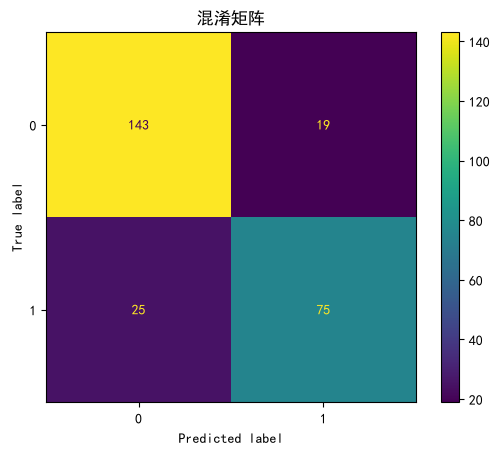

In [32]:
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

ConfusionMatrixDisplay.from_estimator(model, x_test, y_test)
plt.title("混淆矩阵")
plt.show()

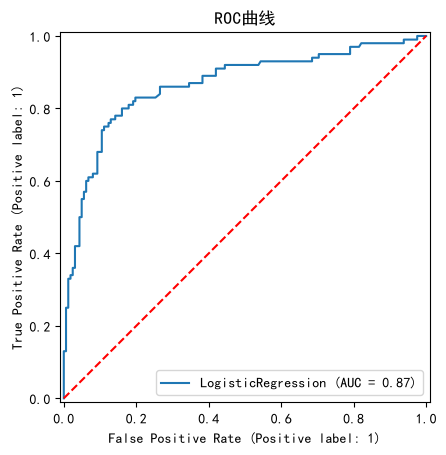

In [33]:
RocCurveDisplay.from_estimator(model, x_test, y_test)
plt.title("ROC曲线")
plt.plot([0,1],[0,1],"r--") # 随机猜测参考线
plt.show()

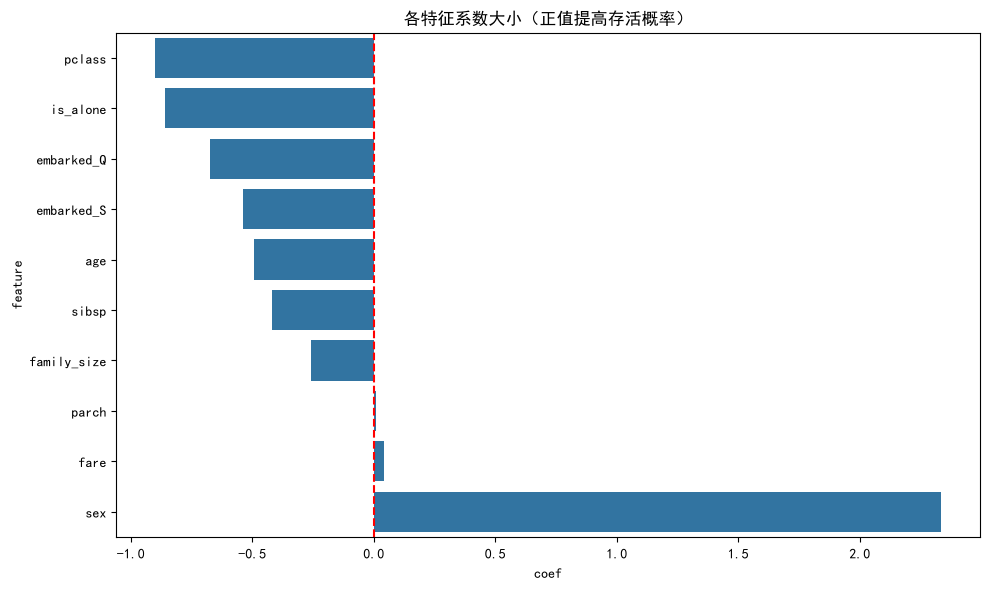

In [34]:
coef_df = pd.DataFrame({
    "feature":x.columns,
    "coef":model.coef_[0]
}).sort_values("coef")

plt.figure(figsize=(10,6))
sns.barplot(data=coef_df, x="coef", y="feature")
plt.axvline(x=0, color="red", ls="--")
plt.title("各特征系数大小（正值提高存活概率）")
plt.tight_layout()
plt.show()

In [35]:
# 保存清洗完成的数据
df.to_csv("D:\\PyCharm\\pychram\\Python_Base_Study\\data\\titanic_cleaned_final.csv", index=False)

In [36]:
import joblib
# 保存模型
joblib.dump(model, "/models/titanic_logistic_model.pkl")

['D:\\PyCharm\\pychram\\Python_Base_Study\\models\\titanic_logistic_model.pkl']